# Textile Defect Classification with a CNN

Multi-class classification of fabric defects (`good`, `hole`, `objects`, `oil spot`, `thread error`) on 64×64 patches from the TILDA dataset.

The train / validation / test split is made **by source image**, so patches cut from the same fabric image never appear in both training and test.

## 1. Setup

In [1]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, f1_score

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

CONFIG = {
    'img_size': 64,
    'batch_size': 32,
    'epochs': 40,
    'learning_rate': 3e-4,
    'test_frac': 0.10,        # share of source images held out for test
    'val_frac': 0.20,         # share of the remaining source images used for validation
    'max_good': 3000,         # undersample the majority class
    'classes': ['good', 'hole', 'objects', 'oil spot', 'thread error'],
    'drop_images': {'203'},   # byte-identical duplicate of image 191
}
FIG_DIR = 'figures'
os.makedirs(FIG_DIR, exist_ok=True)

print('TensorFlow', tf.__version__, '| GPU:', tf.config.list_physical_devices('GPU'))

TensorFlow 2.21.0 | GPU: []


## 2. Download the dataset

In [2]:
# Set TILDA_PATH to use a local copy; otherwise the dataset is downloaded from Kaggle.
DATA_PATH = os.environ.get('TILDA_PATH')
if DATA_PATH is None:
    import kagglehub
    DATA_PATH = kagglehub.dataset_download('angelolmg/tilda-400-64x64-patches')

for c in CONFIG['classes']:
    print(f"{c:13s} {len(os.listdir(os.path.join(DATA_PATH, c))):>6,} patches")

100%|██████████| 142M/142M [00:03<00:00, 42.2MB/s]

Extracting files...


good          23,170 patches
hole             337 patches
objects          837 patches
oil spot         636 patches
thread error     620 patches


## 3. Build the file index

Filenames follow `<image_id>_patch<row>-<col>.png`. Each of the 400 source images is cut into an 8×8 grid; its defect-free tiles are in `good` and its defective tiles in one defect folder.

In [3]:
rows = []
for label, cls in enumerate(CONFIG['classes']):
    for f in os.listdir(os.path.join(DATA_PATH, cls)):
        if f.lower().endswith('.png'):
            rows.append({'path': os.path.join(DATA_PATH, cls, f),
                         'image_id': f.split('_patch')[0],
                         'cls': cls, 'label': label})
df = pd.DataFrame(rows)
df = df[~df.image_id.isin(CONFIG['drop_images'])].reset_index(drop=True)

print('Patches:', len(df), '| source images:', df.image_id.nunique())
print(df.groupby('cls').agg(patches=('path', 'size'), source_images=('image_id', 'nunique')))

Patches: 25536 | source images: 399
              patches  source_images
cls                                 
good            23108            399
hole              337            101
objects           835             99
oil spot          636            100
thread error      620            100


## 4. Split by source image

Each source image is assigned the defect type it contains, and images (not patches) are split with stratification on that type. All patches of an image follow it into the same subset.

In [4]:
defects = df[df.cls != 'good']
image_type = defects.groupby('image_id').cls.first()
images = image_type.index.values

trval_imgs, test_imgs = train_test_split(
    images, test_size=CONFIG['test_frac'], stratify=image_type[images], random_state=SEED)
train_imgs, val_imgs = train_test_split(
    trval_imgs, test_size=CONFIG['val_frac'], stratify=image_type[trval_imgs], random_state=SEED)

split_of = {**{i: 'train' for i in train_imgs}, **{i: 'val' for i in val_imgs}, **{i: 'test' for i in test_imgs}}
df['split'] = df.image_id.map(split_of)
assert df.split.notna().all()

# Undersample 'good' within each split, keeping the same share of good patches per split
parts = []
n_good_total = (df.cls == 'good').sum()
for s, g in df.groupby('split'):
    good = g[g.cls == 'good']
    n_keep = round(CONFIG['max_good'] * len(good) / n_good_total)
    parts += [g[g.cls != 'good'], good.sample(n=n_keep, random_state=SEED)]
data = pd.concat(parts).reset_index(drop=True)

# Leakage check: no source image may appear in more than one split
assert data.groupby('image_id').split.nunique().max() == 1

print(pd.crosstab(data.cls, data.split, margins=True)[['train', 'val', 'test', 'All']])
print('\nSource images per split:', data.groupby('split').image_id.nunique().to_dict())

split         train  val  test   All
cls                                 
good           2162  540   298  3000
hole            246   62    29   337
objects         545  167   123   835
oil spot        462  120    54   636
thread error    461   99    60   620
All            3876  988   564  5428

Source images per split: {'test': 40, 'train': 287, 'val': 72}


## 5. Input pipeline and augmentation

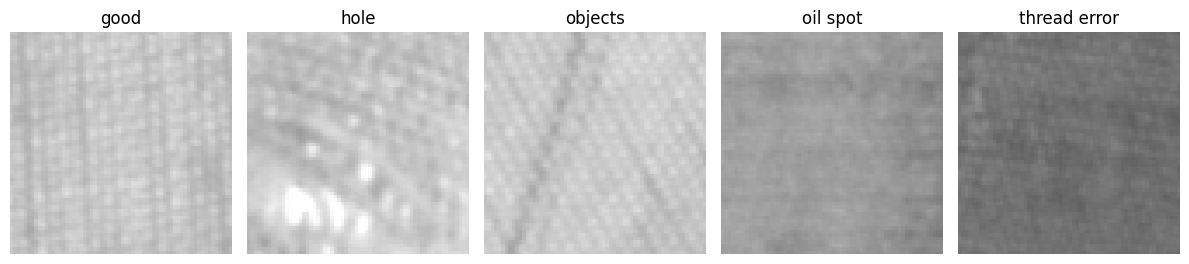

In [5]:
def load(path, label):
    img = tf.io.decode_png(tf.io.read_file(path), channels=3)
    img = tf.cast(img, tf.float32) / 255.0
    return img, label

def augment(img, label):
    img = tf.image.random_flip_left_right(img)
    img = tf.image.random_flip_up_down(img)
    img = tf.image.rot90(img, k=tf.random.uniform([], 0, 4, dtype=tf.int32))
    img = tf.image.random_brightness(img, 0.1)
    img = tf.image.random_contrast(img, 0.9, 1.1)
    return tf.clip_by_value(img, 0.0, 1.0), label

def make_ds(split, training=False):
    d = data[data.split == split]
    ds = tf.data.Dataset.from_tensor_slices((d.path.values, d.label.values))
    if training:
        ds = ds.shuffle(len(d), seed=SEED)
    ds = ds.map(load, num_parallel_calls=tf.data.AUTOTUNE)
    if training:
        ds = ds.map(augment, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.batch(CONFIG['batch_size']).prefetch(tf.data.AUTOTUNE)

train_ds, val_ds, test_ds = make_ds('train', True), make_ds('val'), make_ds('test')

# Show one example per class
fig, axes = plt.subplots(1, 5, figsize=(12, 3))
for ax, cls in zip(axes, CONFIG['classes']):
    p = data[data.cls == cls].path.iloc[0]
    ax.imshow(plt.imread(p)); ax.set_title(cls); ax.axis('off')
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/samples.png', dpi=150); plt.show()

## 6. Model

In [6]:
def conv_block(filters):
    return [layers.Conv2D(filters, 3, padding='same', activation='relu'),
            layers.BatchNormalization(),
            layers.MaxPooling2D()]

s = CONFIG['img_size']
model = models.Sequential(
    [layers.Input((s, s, 3))]
    + conv_block(32) + conv_block(64) + conv_block(128) + conv_block(256)
    + [layers.Flatten(),
       layers.Dense(256, activation='relu'), layers.BatchNormalization(), layers.Dropout(0.5),
       layers.Dense(128, activation='relu'), layers.BatchNormalization(), layers.Dropout(0.3),
       layers.Dense(len(CONFIG['classes']), activation='softmax')])

model.compile(optimizer=tf.keras.optimizers.Adam(CONFIG['learning_rate']),
              loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 8, 8, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 8, 8, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     1,048,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,474,245 (5.62 MB)

 Trainable params: 1,472,517 (5.62 MB)

 Non-trainable params: 1,728 (6.75 KB)

## 7. Training

In [7]:
y_train = data[data.split == 'train'].label.values
counts = np.bincount(y_train, minlength=len(CONFIG['classes']))
class_weight = {i: len(y_train) / (len(counts) * c) for i, c in enumerate(counts)}
print('Class weights:', {CONFIG['classes'][i]: round(w, 2) for i, w in class_weight.items()})

callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6),
]
history = model.fit(train_ds, validation_data=val_ds, epochs=CONFIG['epochs'],
                    class_weight=class_weight, callbacks=callbacks, verbose=2)

Class weights: {'good': np.float64(0.36), 'hole': np.float64(3.15), 'objects': np.float64(1.42), 'oil spot': np.float64(1.68), 'thread error': np.float64(1.68)}
Epoch 1/40
122/122 - 81s - 662ms/step - accuracy: 0.2350 - loss: 2.1394 - val_accuracy: 0.1002 - val_loss: 2.4003 - learning_rate: 3.0000e-04
Epoch 2/40
122/122 - 65s - 533ms/step - accuracy: 0.2758 - loss: 1.9558 - val_accuracy: 0.1002 - val_loss: 4.5938 - learning_rate: 3.0000e-04
Epoch 3/40
122/122 - 82s - 674ms/step - accuracy: 0.2972 - loss: 1.8231 - val_accuracy: 0.1235 - val_loss: 4.8171 - learning_rate: 3.0000e-04
Epoch 4/40
122/122 - 64s - 521ms/step - accuracy: 0.3480 - loss: 1.7264 - val_accuracy: 0.5496 - val_loss: 1.9233 - learning_rate: 3.0000e-04
Epoch 5/40
122/122 - 65s - 536ms/step - accuracy: 0.3707 - loss: 1.6774 - val_accuracy: 0.6012 - val_loss: 1.3804 - learning_rate: 3.0000e-04
Epoch 6/40
122/122 - 65s - 533ms/step - accuracy: 0.3646 - loss: 1.6438 - val_accuracy: 0.3168 - val_loss: 1.6227 - learning_rate

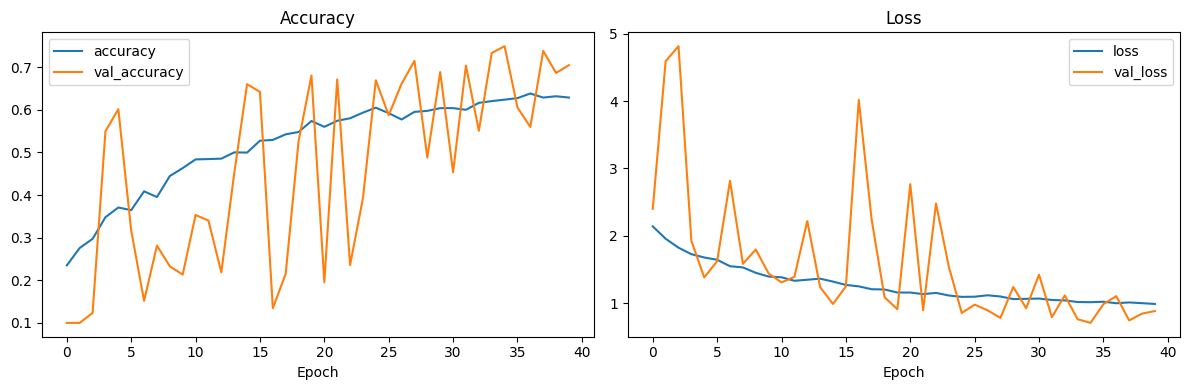

In [8]:
h = pd.DataFrame(history.history)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
h[['accuracy', 'val_accuracy']].plot(ax=axes[0], title='Accuracy')
h[['loss', 'val_loss']].plot(ax=axes[1], title='Loss')
for ax in axes: ax.set_xlabel('Epoch')
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/training_history.png', dpi=150); plt.show()

## 8. Evaluation on the test set

Accuracy: 0.727 | macro F1: 0.609 | majority-class baseline: 0.528

              precision    recall  f1-score   support

        good       0.79      0.96      0.86       298
        hole       0.65      0.69      0.67        29
     objects       0.70      0.44      0.54       123
    oil spot       0.52      0.54      0.53        54
thread error       0.58      0.37      0.45        60

    accuracy                           0.73       564
   macro avg       0.65      0.60      0.61       564
weighted avg       0.71      0.73      0.71       564



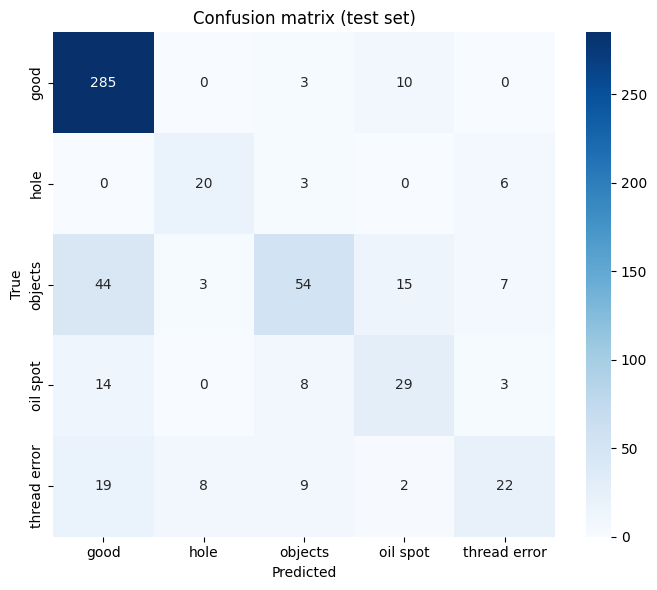

In [9]:
y_true = data[data.split == 'test'].label.values
y_pred = model.predict(test_ds, verbose=0).argmax(axis=1)
names = CONFIG['classes']

acc = (y_true == y_pred).mean()
baseline = (y_true == 0).mean()   # always predicting 'good'
print(f'Accuracy: {acc:.3f} | macro F1: {f1_score(y_true, y_pred, average="macro"):.3f} '
      f'| majority-class baseline: {baseline:.3f}\n')
print(classification_report(y_true, y_pred, target_names=names, digits=2))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=names, yticklabels=names)
plt.xlabel('Predicted'); plt.ylabel('True'); plt.title('Confusion matrix (test set)')
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/confusion_matrix.png', dpi=150); plt.show()

## 9. Example predictions

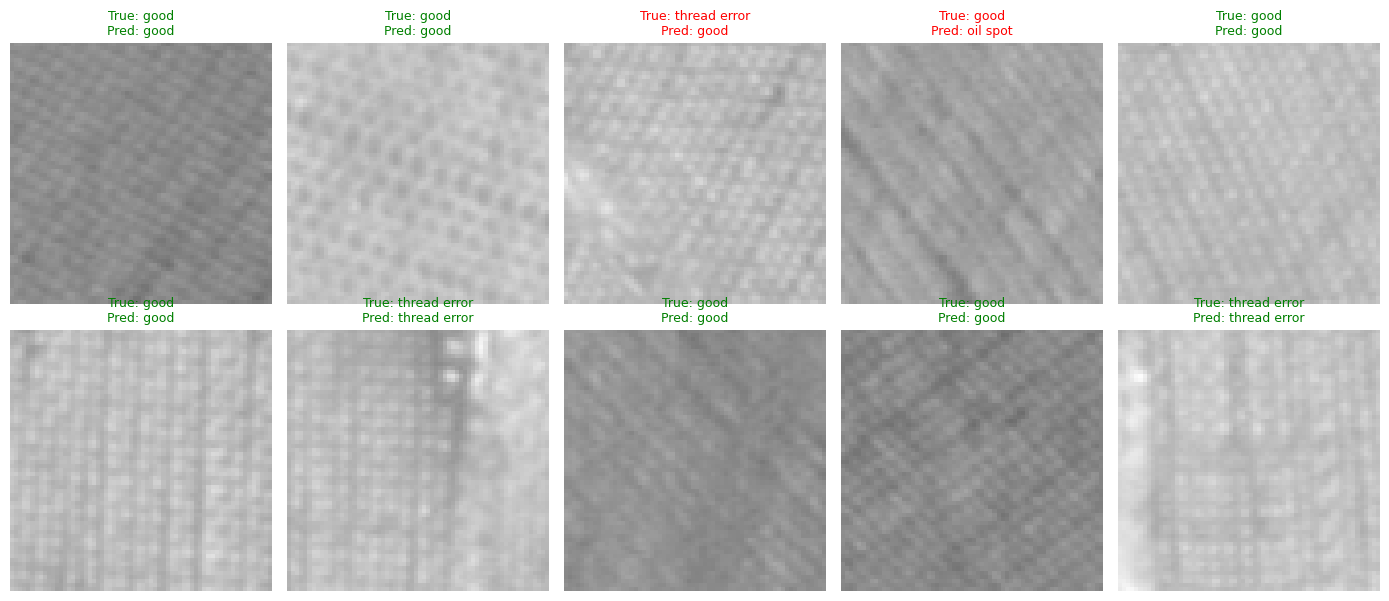

In [10]:
test_df = data[data.split == 'test'].reset_index(drop=True)
idx = np.random.RandomState(SEED).choice(len(test_df), 10, replace=False)
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
for ax, i in zip(axes.ravel(), idx):
    ax.imshow(plt.imread(test_df.path[i]))
    t, p = names[y_true[i]], names[y_pred[i]]
    ax.set_title(f'True: {t}\nPred: {p}', color='green' if t == p else 'red', fontsize=9)
    ax.axis('off')
plt.tight_layout(); plt.savefig(f'{FIG_DIR}/prediction_samples.png', dpi=150); plt.show()

## 10. Save the model

In [11]:
model.save('textile_defect_cnn.keras')

# Optional, in Colab: copy the model and figures to Google Drive
# from google.colab import drive
# drive.mount('/content/drive')
# !mkdir -p /content/drive/MyDrive/TILDA_Project
# !cp -r textile_defect_cnn.keras figures /content/drive/MyDrive/TILDA_Project/